# Лабораторна робота №6
**Тема:** Використання ансамблевих математичних моделей у задачах інтелектуального аналізу даних

## Завдання №1
На основі різних підходів реалізації ансамблевих моделей методів машинного навчання розв’язати задачу класифікації і визначити ефективністі роботи побудованої математичної моделі на основі метрик оцінювання.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# Імпорт ансамблевих моделей, метрик та інструментів розбиття
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv('diabetes.xls')

In [5]:
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [9]:
# Видокремлення ознак (X) та цільової змінної (y — наявність діабету)
X = df.drop(columns=['Outcome']).values
y = df['Outcome'].values

In [10]:
# Розбиття даних на тренувальну та тестову вибірки зі збереженням балансу класів (stratify)
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

In [11]:
# ==========================================
# МОДЕЛЬ 1: Випадковий ліс (Random Forest)
# ==========================================
# Ініціалізація та навчання моделі (100 дерев)
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model = random_forest.fit(x_train, y_train)

In [12]:
# Передбачення та розрахунок точності (Accuracy)
rf_predictions = rf_model.predict(x_test)
print(
    '\nRandom Forest Accuracy: {:.2f}'.format(
        accuracy_score(y_test, rf_predictions)
    )
)


Random Forest Accuracy: 0.75


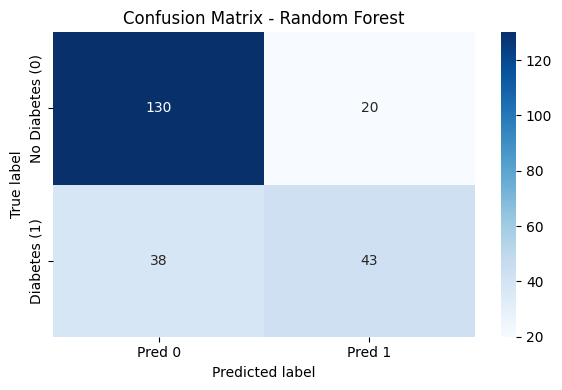

In [14]:
# Побудова матриці плутанини (Confusion Matrix) для Random Forest
plt.figure(figsize=(6, 4))
conf_matrix = confusion_matrix(y_test, rf_predictions)
conf_df = pd.DataFrame(
    conf_matrix,
    index=['No Diabetes (0)', 'Diabetes (1)'],
    columns=['Pred 0', 'Pred 1'],
)
sns.heatmap(conf_df, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

In [15]:
# Аналіз важливості ознак (Feature Importance) для Random Forest
feature_names = df.drop(columns=['Outcome']).columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'RF Importance': rf_model.feature_importances_,
})

In [16]:
# ==========================================
# МОДЕЛЬ 2: Градієнтний бустинг (Gradient Boosting)
# ==========================================
# Ініціалізація та навчання моделі градієнтного бустингу
gradient_boosting = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model = gradient_boosting.fit(x_train, y_train)

# Оцінка точності (Accuracy) для градієнтного бустингу
print(
    'Gradient Boosting Accuracy: {:.2f}'.format(
        gb_model.score(x_test, y_test)
    )
)

Gradient Boosting Accuracy: 0.76


In [17]:
# Додавання та порівняння важливості ознак для Gradient Boosting
feature_importance_df['GB Importance'] = gb_model.feature_importances_
print('\nПорівняння важливості ознак (Random Forest vs Gradient Boosting):')
print(feature_importance_df.sort_values(by='RF Importance', ascending=False))


Порівняння важливості ознак (Random Forest vs Gradient Boosting):
                    Feature  RF Importance  GB Importance
1                   Glucose       0.272615       0.402788
5                       BMI       0.150912       0.178401
7                       Age       0.130462       0.138260
6  DiabetesPedigreeFunction       0.118209       0.121475
0               Pregnancies       0.096181       0.049167
2             BloodPressure       0.089232       0.038777
4                   Insulin       0.073178       0.052632
3             SkinThickness       0.069211       0.018500
